# TAM–SAM–SOM con Monte Carlo: dimensionar un mercado sin fingir precisión

**Perfil:** Estrategia, innovación y venture capital  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Una presentación a inversionistas suele dar *un* número para el mercado ("US$ 4.200 M"). Pero cada insumo es incierto y algunos están correlacionados. ¿Cómo se propaga esa incertidumbre al TAM, al SAM y al SOM? ¿Qué insumos mandan? ¿Qué pasa cuando los expertos son **sobreconfiados** en sus rangos?

## Recorrido

1. Modelo *bottom-up*: empresas × fracción elegible × ticket anual, con rangos de 90 % (lognormales/beta).
2. **Propagación Monte Carlo** y verificación con la fórmula cerrada del producto de lognormales.
3. **Correlación entre insumos** y su efecto en la media (sin ser evidente en la mediana).
4. **Adopción de Bass** con parámetros inciertos: de TAM a SAM y SOM en 5 años.
5. **Sensibilidad:** qué insumo explica la varianza (correlaciones de rango y tornado).
6. **Sobreconfianza experta:** cuándo el intervalo del resultado deja de cubrir la verdad.
7. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy import stats, integrate

## 2. Modelo bottom-up y rangos de entrada

$$\text{TAM}=N\cdot f\cdot A$$

con $N$ el número de empresas en el segmento, $f$ la fracción **elegible** (cumple los requisitos técnicos) y $A$ el ticket anual en USD. Los expertos dan **rangos de 90 %** (percentiles 5–95); para $N$ y $A$ se ajusta una lognormal, para $f$ una Beta con la media del rango.

| insumo | P5 | P95 | distribución |
|---|---|---|---|
| $N$ (empresas) | 50.000 | 200.000 | lognormal |
| $f$ (elegibles) | 20 % | 55 % | Beta |
| $A$ (USD/año) | 2.000 | 12.000 | lognormal |

In [2]:
Z95 = stats.norm.ppf(0.95)
def logn_desde_rango(p5, p95): 
    mu = (np.log(p5) + np.log(p95)) / 2; sd = (np.log(p95) - np.log(p5)) / (2 * Z95); return mu, sd

MU_N, SD_N = logn_desde_rango(50_000, 200_000); MU_A, SD_A = logn_desde_rango(2_000, 12_000)
# Beta con media 0.375 y P5/P95 aprox 0.20/0.55: se busca la concentracion k
from scipy import optimize
def beta_desde_rango(p5, p95):
    def err(k):
        m = (p5 + p95) / 2; a, b = m * k, (1 - m) * k; return (stats.beta.ppf(0.05, a, b) - p5) ** 2 + (stats.beta.ppf(0.95, a, b) - p95) ** 2
    k = optimize.minimize_scalar(err, bounds=(2, 400), method="bounded").x; m = (p5 + p95) / 2; return m * k, (1 - m) * k
A_F, B_F = beta_desde_rango(0.20, 0.55)
print(f"N ~ LN(mu={MU_N:.3f}, sd={SD_N:.3f});  A ~ LN(mu={MU_A:.3f}, sd={SD_A:.3f});  f ~ Beta({A_F:.1f}, {B_F:.1f})")
print(f"Rangos recuperados: f P5/P95 = {stats.beta.ppf(0.05, A_F, B_F):.3f}/{stats.beta.ppf(0.95, A_F, B_F):.3f};  N P5/P95 = {np.exp(MU_N - Z95 * SD_N):,.0f}/{np.exp(MU_N + Z95 * SD_N):,.0f}")

N ~ LN(mu=11.513, sd=0.421);  A ~ LN(mu=8.497, sd=0.545);  f ~ Beta(7.5, 12.4)
Rangos recuperados: f P5/P95 = 0.208/0.557;  N P5/P95 = 50,000/200,000


## 3. Propagación y verificación analítica

Con $N$ y $A$ **independientes** y $f$ independiente, $\log\text{TAM}$ no es normal exacta por $f$, pero el producto $N\cdot A$ sí es lognormal con $\mu=\mu_N+\mu_A$ y $\sigma^2=\sigma_N^2+\sigma_A^2$. Se verifica esa fórmula con la simulación como control de la implementación, y luego se simula el TAM completo.

In [3]:
rng = np.random.default_rng(SEED); M = 400_000
N_ = np.exp(rng.normal(MU_N, SD_N, M)); A_ = np.exp(rng.normal(MU_A, SD_A, M)); F_ = rng.beta(A_F, B_F, M)
NA = N_ * A_; mu_na, sd_na = MU_N + MU_A, np.hypot(SD_N, SD_A)
chk = pd.DataFrame({"simulado": [np.median(NA), NA.mean(), np.log(NA).std()], "formula": [np.exp(mu_na), np.exp(mu_na + sd_na ** 2 / 2), sd_na]}, index=["mediana", "media", "sd(log)"])
chk["error_rel"] = chk.simulado / chk.formula - 1
print(chk.round(4).to_string())
TAM = N_ * F_ * A_
q = np.percentile(TAM, [5, 25, 50, 75, 95]) / 1e6
print(f"\nTAM (millones USD): P5={q[0]:,.0f}  P25={q[1]:,.0f}  mediana={q[2]:,.0f}  P75={q[3]:,.0f}  P95={q[4]:,.0f}  media={TAM.mean() / 1e6:,.0f}")
print(f"'Punto central' ingenuo (medianas de insumos): {np.exp(MU_N) * (A_F / (A_F + B_F)) * np.exp(MU_A) / 1e6:,.0f} M")

                simulado          formula  error_rel
mediana 489,774,567.6580 489,897,948.5566    -0.0003
media   621,572,707.2248 620,988,630.8533     0.0009
sd(log)           0.6890           0.6886     0.0005

TAM (millones USD): P5=51  P25=106  mediana=177  P75=293  P95=600  media=233
'Punto central' ingenuo (medianas de insumos): 184 M


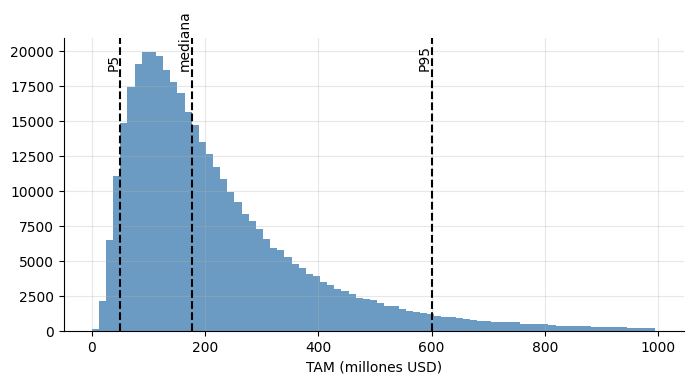

Lectura:
  El intervalo 90% del TAM va de 51 M a 600 M: un factor de 11.9 entre extremos. Presentar solo la mediana (177 M) oculta esa amplitud.
  La media (233 M) supera a la mediana en 32%: distribucion asimetrica a la derecha, tipica de productos de variables positivas.


In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8)); ax.hist(TAM / 1e6, bins=np.linspace(0, np.percentile(TAM, 99) / 1e6, 80), color="steelblue", alpha=.8)
for v, l in zip(q[[0, 2, 4]], ("P5", "mediana", "P95")): ax.axvline(v, c="k", ls="--"); ax.text(v, ax.get_ylim()[1] * .9, l, rotation=90, ha="right")
ax.set_xlabel("TAM (millones USD)"); plt.show()
print("Lectura:")
print(f"  El intervalo 90% del TAM va de {q[0]:,.0f} M a {q[4]:,.0f} M: un factor de {q[4] / q[0]:.1f} entre extremos. Presentar solo la mediana ({q[2]:,.0f} M) oculta esa amplitud.")
print(f"  La media ({TAM.mean() / 1e6:,.0f} M) supera a la mediana en {TAM.mean() / np.median(TAM) - 1:.0%}: distribucion asimetrica a la derecha, tipica de productos de variables positivas.")

## 4. Correlación entre insumos

Las empresas más numerosas son pequeñas y pagan menos: $\log N$ y $\log A$ están **correlacionados negativamente**. Para un par lognormal con correlación $\rho$, $E[NA]=E[N]E[A]\,e^{\rho\,\sigma_N\sigma_A}$ pero la **mediana** del producto no depende de $\rho$. Se verifica esa propiedad y se mide el efecto sobre el intervalo.

In [5]:
filas = []
for rho in (-0.6, -0.3, 0.0, 0.3, 0.6):
    rg = np.random.default_rng(11); z1 = rg.standard_normal(M); z2 = rho * z1 + np.sqrt(1 - rho ** 2) * rg.standard_normal(M)
    Nn = np.exp(MU_N + SD_N * z1); Aa = np.exp(MU_A + SD_A * z2); T = Nn * Aa * rg.beta(A_F, B_F, M)
    p5, p50, p95 = np.percentile(T, [5, 50, 95]) / 1e6
    filas.append({"rho": rho, "mediana": p50, "P5": p5, "P95": p95, "media": T.mean() / 1e6, "media/E[N]E[A]E[f]": T.mean() / (np.exp(MU_N + SD_N ** 2 / 2) * np.exp(MU_A + SD_A ** 2 / 2) * A_F / (A_F + B_F)), "teorico": np.exp(rho * SD_N * SD_A)})
cor = pd.DataFrame(filas).set_index("rho"); cor.round(3)

,mediana,P5,P95,media,media/E[N]E[A]E[f],teorico
rho,,,,,,
-0.6000,177.8800,71.3960,419.0270,202.9170,0.8710,0.8710
-0.3000,177.2690,59.4810,508.7960,217.3500,0.9330,0.9330
0.0000,177.0120,50.6050,600.4640,232.8140,1.0000,1.0000
0.3000,176.5790,44.0470,693.1950,249.3890,1.0710,1.0710
0.6000,176.4290,38.7700,789.1050,267.1570,1.1470,1.1480


In [6]:
print("Lectura:")
print(f"  La mediana apenas cambia con rho ({cor['mediana'].min():,.0f}-{cor['mediana'].max():,.0f} M): la correlacion no mueve el 'centro tipico'.")
print(f"  La MEDIA si cambia: con rho=-0.6 es {cor.loc[-0.6, 'media']:,.0f} M y con rho=+0.6 es {cor.loc[0.6, 'media']:,.0f} M ({cor.loc[0.6, 'media'] / cor.loc[-0.6, 'media'] - 1:+.0%}), y el ancho del intervalo tambien ({cor.loc[-0.6, 'P95'] / cor.loc[-0.6, 'P5']:.1f}x vs {cor.loc[0.6, 'P95'] / cor.loc[0.6, 'P5']:.1f}x).")
print("  Ignorar una correlacion negativa plausible sobreestima la incertidumbre y la media: la omision no es neutra.")

Lectura:
  La mediana apenas cambia con rho (176-178 M): la correlacion no mueve el 'centro tipico'.
  La MEDIA si cambia: con rho=-0.6 es 203 M y con rho=+0.6 es 267 M (+32%), y el ancho del intervalo tambien (5.9x vs 20.4x).
  Ignorar una correlacion negativa plausible sobreestima la incertidumbre y la media: la omision no es neutra.


## 5. De TAM a SAM y SOM con adopción de Bass

El **SAM** es la parte del TAM que el producto puede atender en 5 años dada la adopción: $\text{SAM}_5=\text{TAM}\cdot F(5)$, con la curva de Bass
$$F(t)=\frac{1-e^{-(p+q)t}}{1+(q/p)\,e^{-(p+q)t}},$$
$p$ = innovación, $q$ = imitación. El **SOM** es la cuota que la empresa captura del SAM: $\text{SOM}=\text{SAM}\cdot s$ con $s\sim\text{Beta}$ (media 8 %). Se verifica $F(t)$ contra la integración numérica de la ecuación diferencial $F'=(p+qF)(1-F)$.

In [7]:
def bass(t, p, q): 
    e = np.exp(-(p + q) * t); return (1 - e) / (1 + (q / p) * e)

# verificacion contra la EDO
p0, q0 = 0.03, 0.38
sol = integrate.solve_ivp(lambda t, F: (p0 + q0 * F) * (1 - F), (0, 10), [0.0], t_eval=np.linspace(0, 10, 11), rtol=1e-10, atol=1e-12)
err_ode = np.abs(sol.y[0] - bass(sol.t, p0, q0)).max()
print(f"Error maximo Bass cerrado vs EDO: {err_ode:.2e}")

P = np.exp(rng.normal(np.log(0.03), 0.35, M)); Q = np.exp(rng.normal(np.log(0.35), 0.25, M)); S = rng.beta(4, 46, M)
F5 = bass(5.0, P, Q); SAM = TAM * F5; SOM = SAM * S
tab = pd.DataFrame({"P5": [np.percentile(x, 5) / 1e6 for x in (TAM, SAM, SOM)], "P50": [np.median(x) / 1e6 for x in (TAM, SAM, SOM)], "P95": [np.percentile(x, 95) / 1e6 for x in (TAM, SAM, SOM)]}, index=["TAM", "SAM_5a", "SOM_5a"])
tab["P95/P5"] = tab.P95 / tab.P5; tab.round(1)

Error maximo Bass cerrado vs EDO: 1.47e-10


,P5,P50,P95,P95/P5
TAM,50.7000,176.8000,600.4000,11.9000
SAM_5a,14.2000,55.3000,208.9000,14.7000
SOM_5a,0.8000,4.0000,18.5000,23.8000


In [8]:
print("Lectura:")
print(f"  Adopcion a 5 anios (F5): mediana {np.median(F5):.1%}, P5-P95 = {np.percentile(F5, 5):.1%}-{np.percentile(F5, 95):.1%}.")
print(f"  SOM a 5 anios: mediana {tab.loc['SOM_5a', 'P50']:,.1f} M, rango 90% {tab.loc['SOM_5a', 'P5']:,.1f}-{tab.loc['SOM_5a', 'P95']:,.1f} M: factor {tab.loc['SOM_5a', 'P95/P5']:.0f} entre extremos (TAM: {tab.loc['TAM', 'P95/P5']:.1f}; SAM: {tab.loc['SAM_5a', 'P95/P5']:.1f}).")
print("  Cada capa multiplica la incertidumbre: la razon P95/P5 del SOM es el doble de la del TAM, aunque suela presentarse con la misma precision aparente.")
print(f"  Probabilidad de que el SOM supere 20 M: {(SOM > 20e6).mean():.0%}; de que supere 50 M: {(SOM > 50e6).mean():.0%}.")

Lectura:


  Adopcion a 5 anios (F5): mediana 31.6%, P5-P95 = 17.9%-52.3%.
  SOM a 5 anios: mediana 4.0 M, rango 90% 0.8-18.5 M: factor 24 entre extremos (TAM: 11.9; SAM: 14.7).
  Cada capa multiplica la incertidumbre: la razon P95/P5 del SOM es el doble de la del TAM, aunque suela presentarse con la misma precision aparente.
  Probabilidad de que el SOM supere 20 M: 4%; de que supere 50 M: 0%.


## 6. Sensibilidad: ¿qué insumo manda?

Se calculan las **correlaciones de rango (Spearman)** entre cada insumo y el SOM, y el **tornado** de un cambio de P5 a P95 de cada insumo con los demás en su mediana.

In [9]:
ins = {"N": N_, "f": F_, "A": A_, "p (innovacion)": P, "q (imitacion)": Q, "s (cuota)": S}
rho_s = pd.Series({k: stats.spearmanr(v, SOM)[0] for k, v in ins.items()}).sort_values(key=np.abs, ascending=False)
med = {"N": np.exp(MU_N), "f": stats.beta.median(A_F, B_F), "A": np.exp(MU_A), "p (innovacion)": 0.03, "q (imitacion)": 0.35, "s (cuota)": stats.beta.median(4, 46)}
rango = {"N": (50_000, 200_000), "f": (stats.beta.ppf(.05, A_F, B_F), stats.beta.ppf(.95, A_F, B_F)), "A": (2_000, 12_000), "p (innovacion)": (np.exp(np.log(.03) - Z95 * .35), np.exp(np.log(.03) + Z95 * .35)), "q (imitacion)": (np.exp(np.log(.35) - Z95 * .25), np.exp(np.log(.35) + Z95 * .25)), "s (cuota)": (stats.beta.ppf(.05, 4, 46), stats.beta.ppf(.95, 4, 46))}
def som_det(d): return d["N"] * d["f"] * d["A"] * bass(5.0, d["p (innovacion)"], d["q (imitacion)"]) * d["s (cuota)"] / 1e6
torn = {}
for k in med:
    lo = dict(med); hi = dict(med); lo[k], hi[k] = rango[k]; torn[k] = (som_det(lo), som_det(hi))
tor = pd.DataFrame(torn, index=["en_P5", "en_P95"]).T; tor["swing"] = (tor.en_P95 - tor.en_P5).abs(); tor = tor.sort_values("swing", ascending=False)
print("Spearman con el SOM:\n", rho_s.round(3).to_string()); print("\nTornado (SOM en M USD):\n", tor.round(2).to_string())

Spearman con el SOM:
 A                0.5470
s (cuota)        0.5050
N                0.4210
f                0.2960
p (innovacion)   0.2530
q (imitacion)    0.1900

Tornado (SOM en M USD):
                 en_P5  en_P95  swing
A              1.7100 10.2600 8.5500
s (cuota)      1.6000  8.4800 6.8800
N              2.0900  8.3800 6.2800
f              2.3500  6.2900 3.9400
p (innovacion) 2.6300  6.2600 3.6200
q (imitacion)  3.2000  6.1000 2.9000


In [10]:
print("Lectura:")
print(f"  El insumo que mas explica el SOM por rango es {rho_s.index[0]} (Spearman {rho_s.iloc[0]:+.2f}); el segundo, {rho_s.index[1]} ({rho_s.iloc[1]:+.2f}).")
print(f"  El tornado coincide: el mayor swing es {tor.index[0]} ({tor.iloc[0]['swing']:.1f} M) y el menor {tor.index[-1]} ({tor.iloc[-1]['swing']:.1f} M).")
print("  Consecuencia practica: invertir tiempo en estrechar el rango del insumo dominante reduce mas la incertidumbre que pulir los que apenas importan.")

Lectura:
  El insumo que mas explica el SOM por rango es A (Spearman +0.55); el segundo, s (cuota) (+0.50).
  El tornado coincide: el mayor swing es A (8.5 M) y el menor q (imitacion) (2.9 M).
  Consecuencia practica: invertir tiempo en estrechar el rango del insumo dominante reduce mas la incertidumbre que pulir los que apenas importan.


## 7. Sobreconfianza experta

El experto debería dar un rango de 90 % que contenga la verdad el 90 % de las veces. La evidencia empírica muestra que los rangos suelen ser **demasiado estrechos**. Se simula un mundo con verdad conocida: el $\log$ del valor verdadero de cada insumo es $\mu_i+\sigma_i z$; el experto sabe solo $\mu_i+\sigma_i z+\varepsilon$ (error de juicio) pero da el rango como si su incertidumbre fuera $k\cdot\sigma$ con $k<1$ (sobreconfianza). Se mide la **cobertura** del intervalo de 90 % del *resultado* (producto de tres insumos) según $k$.

In [11]:
def cobertura(k, w=0.0, R=1500, M_=500, seed=0):
    # w = parte de la varianza del error de juicio que es COMUN a los tres insumos (p. ej. optimismo compartido)
    rg = np.random.default_rng(seed); cub = 0; cub_ins = 0
    sig = 0.5                                                              # incertidumbre real del experto (desvio en log) por insumo
    for r in range(R):
        verdad = rg.normal(0, 1, 3)                                         # log-valores verdaderos (centrados)
        err = sig * (np.sqrt(1 - w) * rg.standard_normal(3) + np.sqrt(w) * rg.standard_normal())
        centro = verdad + err                                               # estimacion del experto: la verdad mas error de juicio
        dibujos = centro[:, None] + rg.normal(0, k * sig, (3, M_))          # el experto propaga como si los errores fueran independientes, con SD = k*sig
        sim = dibujos.sum(axis=0); lo, hi = np.percentile(sim, [5, 95]); cub += lo <= verdad.sum() <= hi
        cub_ins += (centro[0] - Z95 * k * sig <= verdad[0] <= centro[0] + Z95 * k * sig)
    return cub / R, cub_ins / R

filas = []
for k in (0.4, 0.6, 0.8, 1.0, 1.3):
    ri, ii = cobertura(k, 0.0); rc, _ = cobertura(k, 0.5, seed=1)
    filas.append({"k": k, "cobertura_insumo": ii, "cobertura_resultado": ri, "cobertura_resultado_sesgo_comun": rc})
sob = pd.DataFrame(filas).set_index("k"); sob.round(3)

,cobertura_insumo,cobertura_resultado,cobertura_resultado_sesgo_comun
k,,,
0.4000,0.4940,0.5000,0.3280
0.6000,0.6910,0.6850,0.5040
0.8000,0.8170,0.8140,0.6470
1.0000,0.9010,0.9050,0.7550
1.3000,0.9730,0.9630,0.8690


In [12]:
print("Lectura (objetivo: 90%):")
print(f"  Con k=1 (calibrado) el insumo cubre {sob.loc[1.0, 'cobertura_insumo']:.0%} y el resultado {sob.loc[1.0, 'cobertura_resultado']:.0%}.")
print(f"  Con k=0.6 (rangos 40% mas estrechos) el insumo cubre {sob.loc[0.6, 'cobertura_insumo']:.0%} y el resultado {sob.loc[0.6, 'cobertura_resultado']:.0%}: con errores independientes la sobreconfianza se HEREDA al resultado, no se agrava.")
print(f"  Lo que si la agrava es un sesgo COMUN (optimismo compartido por los tres insumos, la mitad de la varianza del error): con rangos perfectamente calibrados (k=1) la cobertura del resultado cae a {sob.loc[1.0, 'cobertura_resultado_sesgo_comun']:.0%}, porque los errores no se cancelan.")
print("  Remedio practico: ensanchar los rangos expertos y verificar con casos pasados cuyo resultado se conoce, buscando especificamente sesgos compartidos.")

Lectura (objetivo: 90%):
  Con k=1 (calibrado) el insumo cubre 90% y el resultado 91%.
  Con k=0.6 (rangos 40% mas estrechos) el insumo cubre 69% y el resultado 68%: con errores independientes la sobreconfianza se HEREDA al resultado, no se agrava.
  Lo que si la agrava es un sesgo COMUN (optimismo compartido por los tres insumos, la mitad de la varianza del error): con rangos perfectamente calibrados (k=1) la cobertura del resultado cae a 76%, porque los errores no se cancelan.
  Remedio practico: ensanchar los rangos expertos y verificar con casos pasados cuyo resultado se conoce, buscando especificamente sesgos compartidos.


## 8. Pruebas automáticas

In [13]:
# 8.1 producto de lognormales: formula cerrada coincide con la simulacion
assert chk.error_rel.abs().max() < 0.02
# 8.2 los rangos de entrada se recuperan
assert abs(stats.beta.ppf(0.05, A_F, B_F) - 0.20) < 0.02 and abs(stats.beta.ppf(0.95, A_F, B_F) - 0.55) < 0.02
# 8.3 orden de percentiles y media > mediana
assert (np.diff(q) > 0).all() and TAM.mean() > np.median(TAM)
# 8.4 correlacion: la mediana no cambia, la media sigue exp(rho*sN*sA), crece con rho
assert (cor["mediana"].max() / cor["mediana"].min() - 1) < 0.03
assert np.allclose(cor["media/E[N]E[A]E[f]"], cor["teorico"], rtol=0.06) and cor["media"].is_monotonic_increasing
# 8.5 Bass: coincide con la EDO, F(0)=0, creciente, F(inf)->1
assert err_ode < 1e-6 and bass(0.0, .03, .38) == 0 and (np.diff(bass(np.linspace(0, 30, 50), .03, .38)) > 0).all() and bass(200.0, .03, .38) > 0.999
# 8.6 cada capa amplia la incertidumbre relativa
assert tab.loc["TAM", "P95/P5"] < tab.loc["SAM_5a", "P95/P5"] < tab.loc["SOM_5a", "P95/P5"]
assert (SOM <= SAM).all() and (SAM <= TAM).all()
# 8.7 sensibilidad: Spearman y tornado coinciden en el insumo dominante
assert rho_s.index[0] == tor.index[0] or rho_s.index[0] in tor.index[:2]
assert (rho_s.abs() > 0).all()
# 8.8 sobreconfianza: cobertura cae al estrechar los rangos y la del resultado cae mas que la del insumo
assert sob["cobertura_resultado"].is_monotonic_increasing and abs(sob.loc[1.0, "cobertura_insumo"] - 0.90) < 0.04
assert sob.loc[0.6, "cobertura_insumo"] < 0.78 and abs(sob.loc[0.6, "cobertura_resultado"] - sob.loc[0.6, "cobertura_insumo"]) < 0.06
assert sob.loc[1.0, "cobertura_resultado_sesgo_comun"] < 0.84
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Rangos, no puntos | El TAM tiene un intervalo 90 % de un factor de varias veces entre extremos | Presentar mediana e intervalo, no un solo número |
| Correlación | Cambia la media y el ancho, no la mediana | Modelar la dependencia plausible entre insumos |
| Capas | SAM y SOM amplían la incertidumbre relativa | No dar al SOM la precisión del TAM |
| Sensibilidad | Pocos insumos explican la varianza | Concentrar el esfuerzo de investigación en ellos |
| Sobreconfianza | Rangos estrechos hacen que el resultado deje de cubrir la verdad; un sesgo común lo empeora aun con rangos calibrados | Calibrar con casos pasados, ensanchar rangos y buscar sesgos compartidos |

**Límites que no deben ocultarse**

- Los rangos de entrada son hipotéticos; el valor del ejercicio está en el método, no en las cifras.
- La adopción de Bass supone un mercado homogéneo y un potencial fijo; los productos reales tienen segmentos y shocks.
- El modelo de sobreconfianza supone errores independientes entre insumos; el sesgo común (optimismo) sería peor.